<a href="https://www.kaggle.com/code/samratrm/zee-movies-recsys?scriptVersionId=360042171" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Zee Movie Recommender System

*A Scaler real-world business case study*

## Problem Statement

Zee is a media and entertainment platform with a large catalogue of movies. With so many titles available, users can struggle to find movies they will enjoy, and a poor discovery experience leads to lower engagement. The goal of this project is to build a recommender system that shows each user personalized movie recommendations, based on the ratings they have given and the ratings of other users with similar tastes, in order to improve the overall user experience.

## Objectives

1. Load, clean and merge the ratings, users and movies data into a single dataset.
2. Explore the data to understand rating behavior, user activity, movie popularity, demographics and genres.
3. Build item-based recommenders using Pearson correlation and cosine similarity, including a KNN model on a sparse matrix.
4. Build a matrix factorization model, evaluate it with RMSE and MAPE, and use its learned embeddings to find similar movies and users.
5. Compare the approaches and summarize the business insights.

## Dataset

The data consists of three files:

**ratings.dat** (`UserID::MovieID::Rating::Timestamp`)
- UserIDs range from 1 to 6040 and MovieIDs range from 1 to 3952.
- Ratings are on a 5-star scale, whole stars only.
- Timestamps are in seconds.
- Every user has rated at least 20 movies.

**users.dat** (`UserID::Gender::Age::Occupation::Zip-code`)
- Demographic information is provided voluntarily by users and is not checked for accuracy. Only users who provided some demographic information are included.
- Gender is "M" for male and "F" for female.
- Age is recorded as a range code: 1 = Under 18, 18 = 18-24, 25 = 25-34, 35 = 35-44, 45 = 45-49, 50 = 50-55, 56 = 56+.
- Occupation is recorded as a code from 0 to 20: 0 = other or not specified, 1 = academic/educator, 2 = artist, 3 = clerical/admin, 4 = college/grad student, 5 = customer service, 6 = doctor/health care, 7 = executive/managerial, 8 = farmer, 9 = homemaker, 10 = K-12 student, 11 = lawyer, 12 = programmer, 13 = retired, 14 = sales/marketing, 15 = scientist, 16 = self-employed, 17 = technician/engineer, 18 = tradesman/craftsman, 19 = unemployed, 20 = writer.

**movies.dat** (`MovieID::Title::Genres`)
- Titles match IMDB titles and include the year of release.
- Genres are pipe-separated and drawn from 18 categories: Action, Adventure, Animation, Children's, Comedy, Crime, Documentary, Drama, Fantasy, Film-Noir, Horror, Musical, Mystery, Romance, Sci-Fi, Thriller, War and Western.

## Approach

The project follows the progression of collaborative filtering methods. Memory-based methods (Pearson correlation and cosine similarity) compute similarities directly from the rating matrix. The model-based method (matrix factorization) learns a compact representation of every user and movie from the observed ratings. Each method's recommendations are compared on the same movie, Liar Liar (1997), to show how the approaches differ in practice.

### Data Import and Setup

In [207]:
import os
import kagglehub

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn 

In [208]:
!pip install cmfrec

In [209]:
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/samratrm/zee-dataset/zee_dataset/zee-ratings.dat
/kaggle/input/datasets/samratrm/zee-dataset/zee_dataset/zee-users.dat
/kaggle/input/datasets/samratrm/zee-dataset/zee_dataset/zee-movies.dat


In [210]:
rating = pd.read_csv(
    "/kaggle/input/datasets/samratrm/zee-dataset/zee_dataset/zee-ratings.dat", 
    sep="::", 
    engine="python", 
    header=0
)

users = pd.read_csv(
    "/kaggle/input/datasets/samratrm/zee-dataset/zee_dataset/zee-users.dat", 
    sep="::", 
    engine="python", 
    header=0
)

movies = pd.read_csv(
    "/kaggle/input/datasets/samratrm/zee-dataset/zee_dataset/zee-movies.dat", 
    sep="::", 
    engine="python", 
    header=0, 
    encoding="latin-1"
)

print(f"Rating DB:{rating.shape}\nUsers: {users.shape}\nMovies: {movies.shape}")

Rating DB:(1000209, 4)
Users: (6040, 5)
Movies: (3883, 3)


In [211]:
rating.head()

,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


In [212]:
users.head()

,UserID,Gender,Age,Occupation,Zip-code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


In [213]:
movies.head()

,Movie ID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [214]:
df = pd.merge(rating, movies, left_on='MovieID', right_on='Movie ID', how='left')
df = pd.merge(df, users, on='UserID', how='left')
df.head()

,UserID,MovieID,Rating,Timestamp,Movie ID,Title,Genres,Gender,Age,Occupation,Zip-code
0,1,1193,5,978300760,1193,One Flew Over the Cuckoo's Nest (1975),Drama,F,1,10,48067
1,1,661,3,978302109,661,James and the Giant Peach (1996),Animation|Children's|Musical,F,1,10,48067
2,1,914,3,978301968,914,My Fair Lady (1964),Musical|Romance,F,1,10,48067
3,1,3408,4,978300275,3408,Erin Brockovich (2000),Drama,F,1,10,48067
4,1,2355,5,978824291,2355,"Bug's Life, A (1998)",Animation|Children's|Comedy,F,1,10,48067


In [215]:
df = df.drop(columns=['Movie ID'])

df = df.rename(columns={
    'UserID': 'user_id',
    'MovieID': 'movie_id',
    'Rating': 'rating',
    'Timestamp': 'timestamp',
    'Title': 'title',
    'Genres': 'genres',
    'Gender': 'gender',
    'Age': 'age',
    'Occupation': 'occupation',
    'Zip-code': 'zip_code'
})

df['timestamp'] = pd.to_datetime(df['timestamp'], unit='s')

df['user_id'] = df['user_id'].astype('int32')
df['movie_id'] = df['movie_id'].astype('int32')
df['rating'] = df['rating'].astype('int8')
df['occupation'] = df['occupation'].astype('category')
df['gender'] = df['gender'].astype('category')
df['zip_code'] = df['zip_code'].astype('category')
df['age'] = df['age'].astype('category')

df.head()

,user_id,movie_id,rating,timestamp,title,genres,gender,age,occupation,zip_code
0,1,1193,5,2000-12-31 22:12:40,One Flew Over the Cuckoo's Nest (1975),Drama,F,1,10,48067
1,1,661,3,2000-12-31 22:35:09,James and the Giant Peach (1996),Animation|Children's|Musical,F,1,10,48067
2,1,914,3,2000-12-31 22:32:48,My Fair Lady (1964),Musical|Romance,F,1,10,48067
3,1,3408,4,2000-12-31 22:04:35,Erin Brockovich (2000),Drama,F,1,10,48067
4,1,2355,5,2001-01-06 23:38:11,"Bug's Life, A (1998)",Animation|Children's|Comedy,F,1,10,48067


In [216]:
age_map = {
    1: "Under 18", 18: "18-24", 25: "25-34", 35: "35-44",
    45: "45-49", 50: "50-55", 56: "56+"
}

occupation_map = {
    0: "other", 1: "academic/educator", 2: "artist", 3: "clerical/admin",
    4: "college/grad student", 5: "customer service", 6: "doctor/health care",
    7: "executive/managerial", 8: "farmer", 9: "homemaker", 10: "K-12 student",
    11: "lawyer", 12: "programmer", 13: "retired", 14: "sales/marketing",
    15: "scientist", 16: "self-employed", 17: "technician/engineer",
    18: "tradesman/craftsman", 19: "unemployed", 20: "writer"
}

df['age_group'] = df['age'].map(age_map)
df['occupation_group'] = df['occupation'].map(occupation_map)

print(df.isna().sum())

df.head()

user_id             0
movie_id            0
rating              0
timestamp           0
title               0
genres              0
gender              0
age                 0
occupation          0
zip_code            0
age_group           0
occupation_group    0
dtype: int64


,user_id,movie_id,rating,timestamp,title,genres,gender,age,occupation,zip_code,age_group,occupation_group
0,1,1193,5,2000-12-31 22:12:40,One Flew Over the Cuckoo's Nest (1975),Drama,F,1,10,48067,Under 18,K-12 student
1,1,661,3,2000-12-31 22:35:09,James and the Giant Peach (1996),Animation|Children's|Musical,F,1,10,48067,Under 18,K-12 student
2,1,914,3,2000-12-31 22:32:48,My Fair Lady (1964),Musical|Romance,F,1,10,48067,Under 18,K-12 student
3,1,3408,4,2000-12-31 22:04:35,Erin Brockovich (2000),Drama,F,1,10,48067,Under 18,K-12 student
4,1,2355,5,2001-01-06 23:38:11,"Bug's Life, A (1998)",Animation|Children's|Comedy,F,1,10,48067,Under 18,K-12 student


In [217]:
age_category_order = ["Under 18", "18-24", "25-34", "35-44", "45-49", "50-55", "56+"]

df['age_group'] = pd.Categorical(
    df['age_group'], 
    categories=age_category_order, 
    ordered=True
)

In [218]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 12 columns):
 #   Column            Non-Null Count    Dtype         
---  ------            --------------    -----         
 0   user_id           1000209 non-null  int32         
 1   movie_id          1000209 non-null  int32         
 2   rating            1000209 non-null  int8          
 3   timestamp         1000209 non-null  datetime64[ns]
 4   title             1000209 non-null  object        
 5   genres            1000209 non-null  object        
 6   gender            1000209 non-null  category      
 7   age               1000209 non-null  category      
 8   occupation        1000209 non-null  category      
 9   zip_code          1000209 non-null  category      
 10  age_group         1000209 non-null  category      
 11  occupation_group  1000209 non-null  category      
dtypes: category(6), datetime64[ns](1), int32(2), int8(1), object(2)
memory usage: 38.3+ MB


### Feature Engineering

In [219]:
df['genre_count'] = df['genres'].str.count('\\|') +1
df['release_year'] = df['title'].str.extract(r'\((\d{4})\)$').astype('int16')
df.head()

,user_id,movie_id,rating,timestamp,title,genres,gender,age,occupation,zip_code,age_group,occupation_group,genre_count,release_year
0,1,1193,5,2000-12-31 22:12:40,One Flew Over the Cuckoo's Nest (1975),Drama,F,1,10,48067,Under 18,K-12 student,1,1975
1,1,661,3,2000-12-31 22:35:09,James and the Giant Peach (1996),Animation|Children's|Musical,F,1,10,48067,Under 18,K-12 student,3,1996
2,1,914,3,2000-12-31 22:32:48,My Fair Lady (1964),Musical|Romance,F,1,10,48067,Under 18,K-12 student,2,1964
3,1,3408,4,2000-12-31 22:04:35,Erin Brockovich (2000),Drama,F,1,10,48067,Under 18,K-12 student,1,2000
4,1,2355,5,2001-01-06 23:38:11,"Bug's Life, A (1998)",Animation|Children's|Comedy,F,1,10,48067,Under 18,K-12 student,3,1998


In [220]:
df['decade'] = (df['release_year'] // 10) * 10
df.head()

,user_id,movie_id,rating,timestamp,title,genres,gender,age,occupation,zip_code,age_group,occupation_group,genre_count,release_year,decade
0,1,1193,5,2000-12-31 22:12:40,One Flew Over the Cuckoo's Nest (1975),Drama,F,1,10,48067,Under 18,K-12 student,1,1975,1970
1,1,661,3,2000-12-31 22:35:09,James and the Giant Peach (1996),Animation|Children's|Musical,F,1,10,48067,Under 18,K-12 student,3,1996,1990
2,1,914,3,2000-12-31 22:32:48,My Fair Lady (1964),Musical|Romance,F,1,10,48067,Under 18,K-12 student,2,1964,1960
3,1,3408,4,2000-12-31 22:04:35,Erin Brockovich (2000),Drama,F,1,10,48067,Under 18,K-12 student,1,2000,2000
4,1,2355,5,2001-01-06 23:38:11,"Bug's Life, A (1998)",Animation|Children's|Comedy,F,1,10,48067,Under 18,K-12 student,3,1998,1990


In [221]:
df.isna().sum()

user_id             0
movie_id            0
rating              0
timestamp           0
title               0
genres              0
gender              0
age                 0
occupation          0
zip_code            0
age_group           0
occupation_group    0
genre_count         0
release_year        0
decade              0
dtype: int64

In [222]:
df.duplicated().sum()

np.int64(0)

#### **Summary:**
* Imported three separate datasets (`ratings`, `users`, and `movies`) using pandas with the correct custom separator and header configurations.
* Combined the tables into a single master DataFrame using left joins on the movie and user ID columns.
* Cleaned up the columns by dropping redundant fields, renaming everything into a clean lowercase `snake_case` style, and converting attributes like gender, age, and zip code into categorical types.
* Converted the raw epoch numbers into readable datetime timestamps and extracted the release year from the movie titles, decade from release year and genre count form genre list.
* Checked the dataset for any missing values and verified that there are no duplicate rows.

## Exploratory Data Analysis

### Sparsity

Sparsity measures the proportion of **missing or empty data** relative to the total possible interactions in a dataset or user-item matrix.

#### Formula

$$\text{Sparsity} = 1 - \left( \frac{\text{Total Actual Ratings}}{\text{Total Possible Ratings (Users} \times \text{Movies)}} \right)$$

#### Why We Need It

* **Memory Management:** In recommendation systems, most users only rate a tiny fraction of items, resulting in a matrix that is $95\%+$ empty. Knowing the sparsity helps determine whether to use standard data structures or memory-efficient **sparse matrices** (`scipy.sparse`).
* **Algorithm Selection:** High sparsity dictates the choice of machine learning models. It justifies using **Collaborative Filtering** (like Matrix Factorization or SVD) rather than standard density-based models to uncover hidden patterns from scarce data.

In [223]:
n_users = df['user_id'].nunique()
n_movies = df['movie_id'].nunique()
n_ratings = len(df)
sparsity = 1 - (n_ratings / (n_users*n_movies))

print(f"Matrix Sparsity: {sparsity * 100:.2f}%")

Matrix Sparsity: 95.53%


### Rating Distribution Analysis

In [224]:
print(f"Invalid rating count : {df.loc[(df['rating'] <= 0) |( df['rating'] > 5), 'rating'].count()}")

print(f"Mean Rating :{df['rating'].mean():.2f}")

Invalid rating count : 0
Mean Rating :3.58


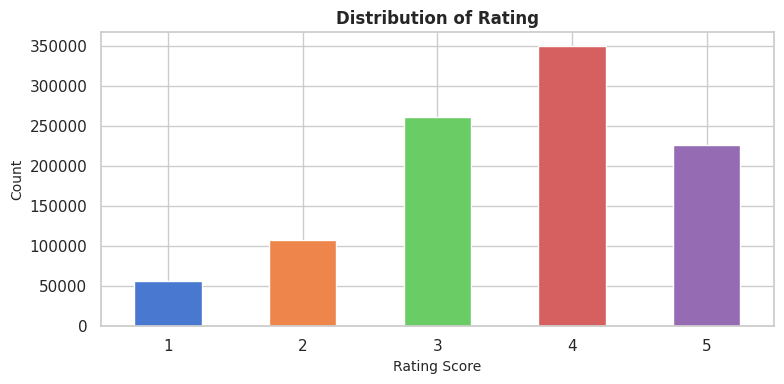

In [225]:
sns.set_theme(style='whitegrid')
plt.figure(figsize=(8,4))
ax = df['rating'].value_counts().sort_index().plot(kind='bar', color=sns.color_palette('muted'))

plt.title('Distribution of Rating', fontsize=12, fontweight='bold')
plt.xlabel('Rating Score', fontsize=10)
plt.ylabel('Count', fontsize=10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [226]:
(df['rating'].apply(lambda x: 1 if x>2 else 0)).value_counts(normalize=True) * 100

rating
1    83.630321
0    16.369679
Name: proportion, dtype: float64

#### **Insights:**

- Users tend to leave positive reviews more often than negative ones, with 5, 4 and 3 stars being `~83%` and 1-star or 2-star ratings happening less frequently `~16%` . This creates a positive rating bias where the overall mean is 3.6 rating, reflecting that people naturally prefer to rate movies they enjoy.
- So, this means 5 star ratings are more common than 1 star ratings.

### User Review Distribution Analysis

In [227]:
df[['user_id']].groupby('user_id').size().describe()

count    6040.000000
mean      165.597517
std       192.747029
min        20.000000
25%        44.000000
50%        96.000000
75%       208.000000
max      2314.000000
dtype: float64

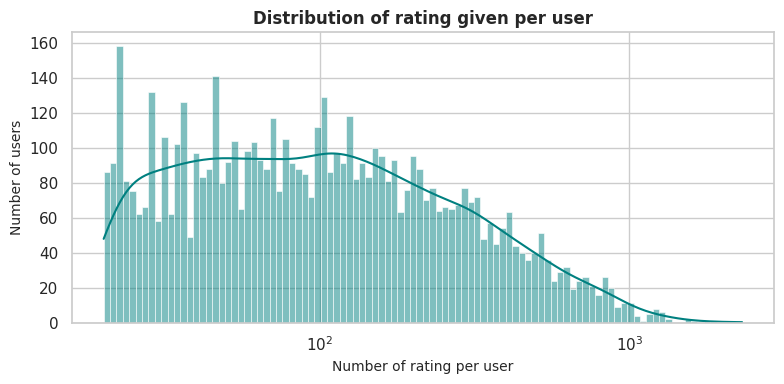

In [228]:
user_rating_counts = df['user_id'].value_counts()

plt.figure(figsize=(8, 4))
sns.histplot(data = user_rating_counts, kde=True, color='teal', bins=100, log_scale=True)

plt.title('Distribution of rating given per user', fontsize=12, fontweight='bold')
plt.xlabel('Number of rating per user', fontsize=10)
plt.ylabel('Number of users', fontsize=10)
plt.tight_layout()
plt.show()

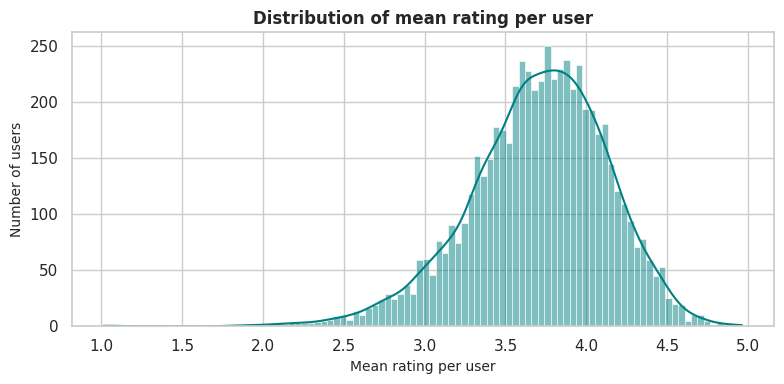

In [229]:
user_rating_mean = df.groupby('user_id')['rating'].mean()

plt.figure(figsize=(8, 4))
sns.histplot(data = user_rating_mean, kde=True, color='teal', bins=100)

plt.title('Distribution of mean rating per user', fontsize=12, fontweight='bold')
plt.xlabel('Mean rating per user', fontsize=10)
plt.ylabel('Number of users', fontsize=10)
plt.tight_layout()
plt.show()

In [230]:
user_rating_mean.describe()

count    6040.000000
mean        3.702705
std         0.429622
min         1.015385
25%         3.444444
50%         3.735294
75%         4.000000
max         4.962963
Name: rating, dtype: float64

#### **Insights:**

- The number of ratings per user is heavily right-skewed. The average user has rated about 166 movies, but the median is only 96, because a small group of very active users pulls the average up. The most active user rated 2,314 movies, while the middle half of users rated between 44 and 208.

- The distribution stops sharply at 20 ratings, which confirms the dataset was pre-filtered to users with at least 20 ratings rather than reflecting natural behavior. This hides the cold-start problem. On a real platform, many users have rated only a handful of movies or none at all, and nothing built or evaluated on this data will show how the recommender performs for them.

### Movie Review Count Distribution

In [231]:
print(f"Movies that has no reviews :{movies['Movie ID'].nunique() - df['movie_id'].nunique()}")

Movies that has no reviews :177


In [232]:
df[['movie_id']].groupby('movie_id').size().describe()

count    3706.000000
mean      269.889099
std       384.047838
min         1.000000
25%        33.000000
50%       123.500000
75%       350.000000
max      3428.000000
dtype: float64

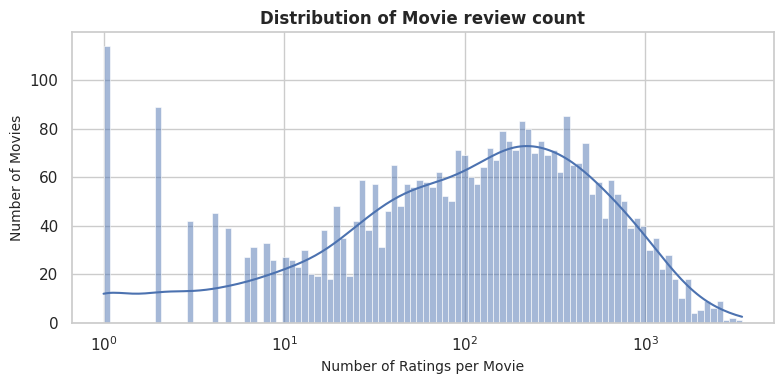

In [233]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df.groupby('movie_id')['rating'].size(), kde=True, bins=100, log_scale=True)

plt.title('Distribution of Movie review count', fontsize=12, fontweight='bold')
plt.xlabel('Number of Ratings per Movie', fontsize=10)
plt.ylabel('Number of Movies', fontsize=10)
plt.tight_layout()
plt.show()

In [234]:
movie_sizes = df.groupby('movie_id').size()

print(f"Mean reviews per movie:   {movie_sizes.mean():.2f}")
print(f"Median reviews per movie: {movie_sizes.median():.2f}")
print(f"Movies with only 1 review: {(movie_sizes == 1).sum()}")

Mean reviews per movie:   269.89
Median reviews per movie: 123.50
Movies with only 1 review: 114


#### **Insights:**
* `4.6%` which is 177 out of 3883 movies has no reviews from the movies dataset. Which is not included in the merged review dataset.
* 114 movies has only one rating.
* The distribution of movie popularity is heavily right-skewed where the median is 123.5 and mean of 270 as most titles struggle to gain traction.
* While the minimum number of reviews a movie receives is **1**, a tiny fraction of blockbuster hits accumulate up to **3,428 reviews**, concentrating the vast majority of viewer attention on a very small set of titles.

### Movie Popularity VS Avg Rating Analysis

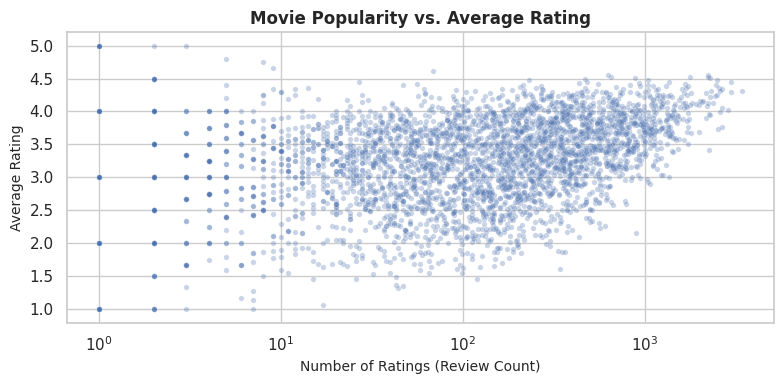

In [235]:
movie_df = df.groupby('movie_id').agg(
    n_reviews=('rating', 'count'),
    mean_rating=('rating', 'mean')
).reset_index()

plt.figure(figsize=(8, 4))
sns.scatterplot(data=movie_df, x='n_reviews', y='mean_rating', alpha=0.3, s=15)
plt.xscale('log')

plt.title('Movie Popularity vs. Average Rating', fontsize=12, fontweight='bold')
plt.xlabel('Number of Ratings (Review Count)', fontsize=10)
plt.ylabel('Average Rating', fontsize=10)
plt.tight_layout()
plt.show()

#### **Insights:**

- The plot has a clear funnel shape. Movies with only a few ratings are spread across the whole range from 1 to 5, but the spread narrows as the number of ratings grows. Past about 100 ratings, most averages fall between 2.5 and 4.3, and past 1,000 ratings nearly all of them sit between 3.5 and 4.5. An average built from a handful of ratings is mostly noise.

- The extreme averages of 5.0 and 1.0 only show up for movies with fewer than about 10 ratings. The horizontal stripes on the far left of the plot show why. With n ratings, the average can only move in steps of 1/n, so a movie with one rating can only have a whole-number average and a movie with two can only land on half steps.

- Popular movies are rarely bad. The average rating rises with popularity, and the most rated films cluster between 3.5 and 4.5. This is a selection effect: good movies attract more viewers, while poorly received ones never build an audience.

- This affects how the recommender should be built. Ranking movies by raw average would push obscure films with a single rating to the top, so popularity has to be taken into account, for example with a damped mean that pulls low-count movies toward the overall average. Movies below a minimum number of ratings will also be left out of the user-item matrix, because similarity scores computed from only a few shared raters can't be trusted.

In [236]:
df['rating'].std()

np.float64(1.117101845373258)

In [237]:
total_movies = len(movie_df)
total_rating = movie_df['n_reviews'].sum()

rows = []
for N in [20, 33, 50, 75,100, 200, 500]:
    kept = movie_df[movie_df['n_reviews']>=N]
    rows.append({
        'N': N,
        'movies_kept': len(kept),
        'pct_movies':  len(kept) / total_movies * 100,
        'pct_ratings': kept['n_reviews'].sum() / total_rating * 100,
    })
pd.DataFrame(rows)

,N,movies_kept,pct_movies,pct_ratings
0,20,3043,82.110092,99.528399
1,33,2784,75.121425,98.863637
2,50,2514,67.835942,97.763467
3,75,2223,59.983810,95.981240
4,100,2019,54.479223,94.202812
5,200,1426,38.478144,85.555119
6,500,618,16.675661,59.458773


#### **Note:**

To decide which movies to keep, I compared several minimum rating thresholds by looking at how many movies and how many ratings each one retains. Raising the threshold from 20 to 100 removes a large share of movies (82% kept down to 54%) but only a small share of ratings (99.5% down to 94%), since the movies being dropped have very few ratings to begin with. Beyond 100 the loss speeds up, falling to 86% of ratings at 200 and 59% at 500, which means cutting films that people actually watch.


I chose a threshold of 75 ratings. It keeps 2,223 movies (60% of all rated movies) while preserving 96% of all ratings. With a rating standard deviation of about 1.1, the uncertainty in a movie's average at 75 ratings is roughly ±0.13, which is small enough for the averages and similarity scores to be reliable. A higher cutoff would mostly leave blockbusters and make the popularity bias worse, while a lower one would let noisy, barely rated movies into the similarity calculations.

In [238]:
movie_review_cnt_threshold = 75

valid_movies_id = movie_df[movie_df['n_reviews']>=movie_review_cnt_threshold]['movie_id'].to_list()

df_model = df[df['movie_id'].isin(valid_movies_id)].copy()

print(f"New Dataset shape: {df_model.shape} which has {df_model['movie_id'].nunique()} movies; every user has at least {df_model.groupby('user_id')['user_id'].count().min()} ratings per user")

New Dataset shape: (960013, 15) which has 2223 movies; every user has at least 13 ratings per user


#### **Summary: Filtering movies by rating count**

- The scatter plot of average rating against number of ratings showed that averages from movies with few ratings are unreliable. Movies with only a handful of ratings were spread across the entire 1 to 5 range, while movies with many ratings settled into a much narrower band. To keep this noise out of the similarity models, I compared several minimum rating thresholds and chose 75 ratings per movie, which balances the number of movies kept against the reliability of their ratings.

- After filtering, the modeling dataset has 960,013 ratings across 2,223 movies. This removes 1,483 rarely rated movies (40% of the rated catalogue) but only 40,196 ratings (about 4% of the total), which confirms that the dropped movies carried very little information. The filtered data is stored separately as `df_model` for building the recommenders, while the full dataset is kept for the exploratory analysis and questionnaire answers.

- And every user still has at least 13 ratings, so no additional user filtering was applied.

### Age and Occupation Analysis

/tmp/ipykernel_49/1267490538.py:5: UserWarning: The palette list has more values (10) than needed (7), which may not be intended.
  sns.barplot(


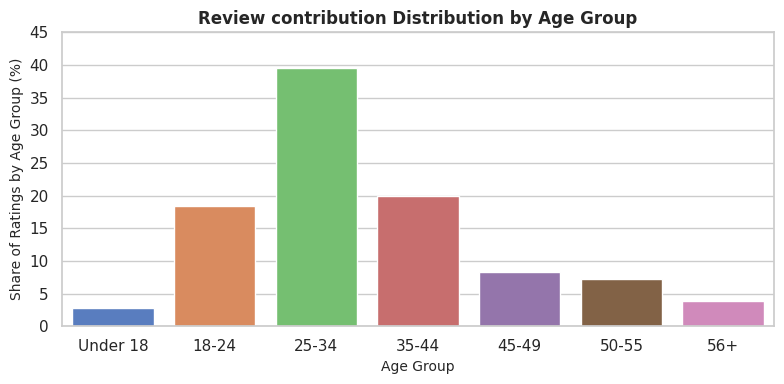

In [239]:
age_df = (df['age_group'].value_counts(normalize=True) * 100).reset_index()
age_df.columns = ['age_group', 'percentage']

plt.figure(figsize=(8, 4))
sns.barplot(
    data=age_df, 
    x='age_group', 
    y='percentage', 
    palette=sns.color_palette('muted'),
    hue='age_group'
)

plt.title('Review contribution Distribution by Age Group', fontsize=12, fontweight='bold')
plt.xlabel('Age Group', fontsize=10)
plt.ylabel('Share of Ratings by Age Group (%)', fontsize=10)
plt.xticks(rotation=0)
plt.ylim(0, 45)
plt.tight_layout()
plt.show()

#### **Insights:**

* **Dominant Cohort:** The `25-34` age group drives the platform with a massive **~40%** review contribution nearly double the share of the second-highest groups (`35-44` at ~20%).
* **Bell-Curve Trend:** Engagement scales up sharply into the mid-twenties, plateaus, and then tapers off on both sides, with the `Under 18` cohort showing the lowest engagement.


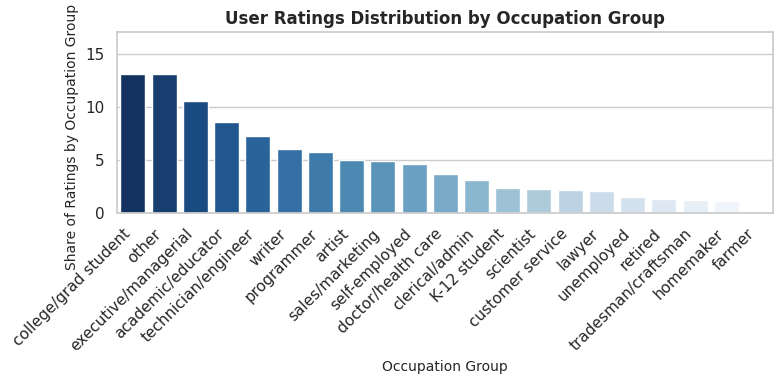

In [240]:
occupation_df = (df['occupation_group'].value_counts(normalize=True) * 100).reset_index()
occupation_df.columns = ['occupation_group', 'percentage']
occupation_df = occupation_df.sort_values(by='percentage', ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(
    data=occupation_df, 
    x='occupation_group', 
    y='percentage', 
    palette='Blues_r',
    hue=occupation_df.index,
    order=occupation_df['occupation_group'],
    legend=False
)

plt.title('User Ratings Distribution by Occupation Group', fontsize=12, fontweight='bold')
plt.xlabel('Occupation Group', fontsize=10)
plt.ylabel('Share of Ratings by Occupation Group (%)', fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 17)
plt.tight_layout()
plt.show()

In [241]:
occupation_df[:2]

,occupation_group,percentage
0,college/grad student,13.100462
1,other,13.047173


#### **Insights:**

- College/grad students contribute the most ratings at 13.1%, narrowly ahead of "other" at 13.0%. Since "other" means the occupation was not specified, college/grad students are the largest identifiable group. Executives and managers follow at about 10.5%, making them the only other group above 10%.

- Activity is concentrated in a handful of occupations. Only 7 of the 21 groups contribute more than 5% of ratings each, and the remaining 14 trail off below 5%, with farmers, homemakers and tradesmen contributing the least.

- The large "other" group also limits how much occupation can tell us. About 13% of ratings come from users whose occupation is unknown, so occupation is a weak signal for personalizing recommendations.

### Gender Review Distribution Analysis

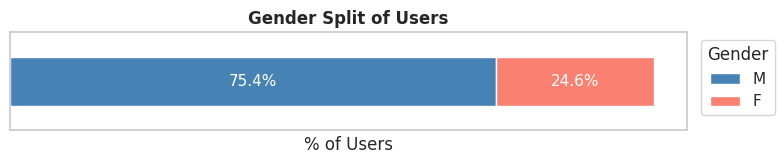

In [242]:
gender_pct = df['gender'].value_counts(normalize=True) * 100
gender_df = gender_pct.to_frame().T

ax = gender_df.plot(kind='barh', stacked=True, figsize=(8, 1.8),
                    color=['steelblue', 'salmon'])

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center', color='white', fontsize=11)

ax.set_yticks([])
ax.set_xticks([])
ax.set_xlabel('% of Users')
ax.set_title('Gender Split of Users', fontweight='bold')
ax.legend(title='Gender', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

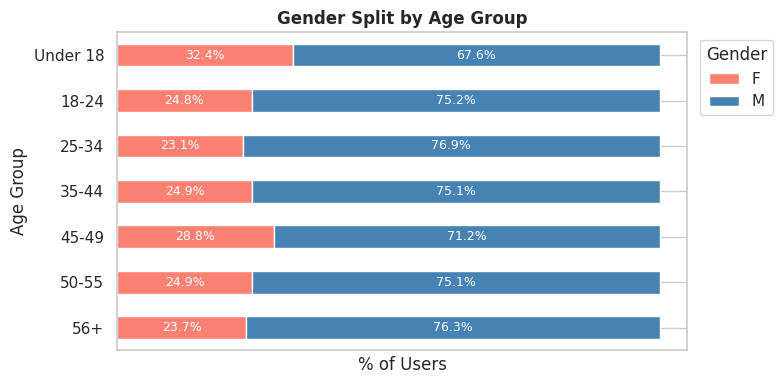

In [243]:
gender_split = pd.crosstab(df['age_group'], df['gender'], normalize='index') * 100

ax = gender_split.plot(kind='barh', stacked=True, figsize=(8, 4),
                       color=['salmon', 'steelblue'])

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center', color='white', fontsize=9)

ax.invert_yaxis()
ax.set_xticks([])
ax.set_xlabel('% of Users')
ax.set_ylabel('Age Group')
ax.set_title('Gender Split by Age Group', fontweight='bold')
ax.legend(title='Gender', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### **Insights:**

- Men account for most of the activity on the platform, contributing roughly three ratings for every one from women. The recommender's training data therefore reflects male viewing preferences more strongly, and female users may get less accurate recommendations as a result.

- The gender split is fairly consistent across age groups. The Under 18 group has a noticeably higher share of female users than the others, but it is one of the smallest groups, so it has little effect on the overall picture.

### Movie Decade Analysis 

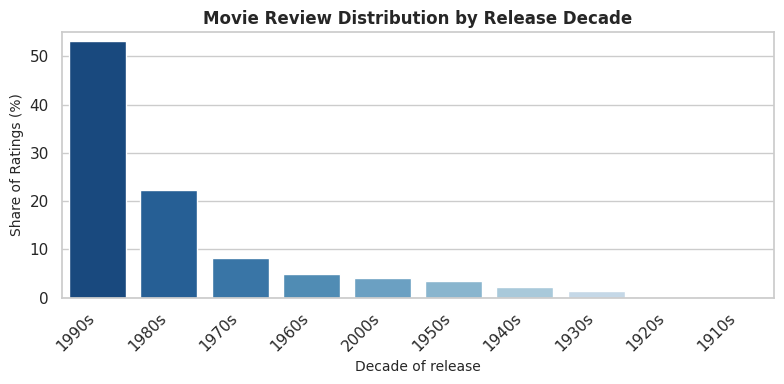

In [244]:
decade_df = (df['decade'].value_counts(normalize=True) * 100).reset_index()
decade_df.columns = ['decade', 'percentage']
decade_df['decade'] = decade_df['decade'].astype(str) + 's'
decade_df = decade_df.sort_values(by='percentage', ascending=False)


plt.figure(figsize=(8, 4))
sns.barplot(
    data = decade_df,
    x='decade',
    y='percentage',
    palette='Blues_r',
    hue='decade',
    # order=decade_df.index,
    legend=False
)

plt.title('Movie Review Distribution by Release Decade', fontsize=12, fontweight='bold')
plt.xlabel('Decade of release', fontsize=10)
plt.ylabel('Share of Ratings (%)', fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 55)
plt.tight_layout()
plt.show()

In [245]:
df['release_year'].max()

np.int16(2000)

#### **Insights:**

- The 1990s dominate the dataset. Movies released in that decade account for roughly 53% of all ratings, and together with the 1980s they account for about 75% of all ratings. The number of ratings grows steadily from the 1910s onward and peaks in the 1990s.

- The sharp drop for the 2000s is not a real decline. That bar covers only a single year, 2000, because the ratings were collected around that time and later releases are not in the data.

- For the recommender, this means both the catalogue and viewer attention are concentrated on recent films. Older movies have fewer ratings, so their similarity scores rest on less data, and the model will naturally lean toward recommending 1990s titles.

### Genre Analysis

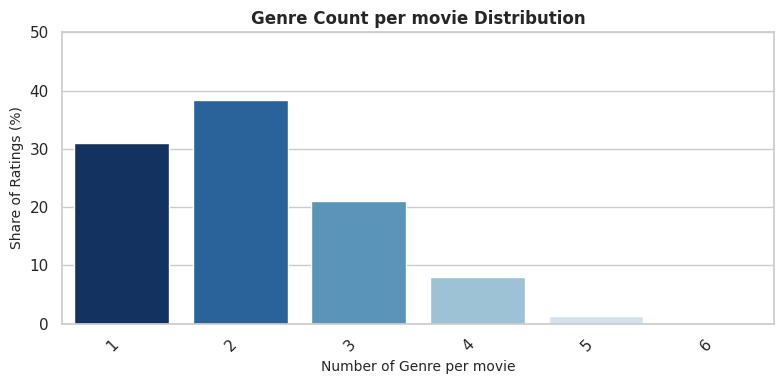

In [246]:
genre_cnt_df = (df['genre_count'].value_counts(normalize=True) * 100).reset_index()

plt.figure(figsize=(8, 4))
sns.barplot(data=genre_cnt_df, x='genre_count', y='proportion', legend=False, hue='genre_count', palette='Blues_r')

plt.title('Genre Count per movie Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Number of Genre per movie', fontsize=10)
plt.ylabel('Share of Ratings (%)', fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

In [247]:
genre_dummies = df['genres'].str.get_dummies(sep='|')
genre_df = (100 * genre_dummies.sum(axis=0) / len(df)).reset_index()
genre_df.columns = ['genre', 'count']
genre_df = genre_df.sort_values(by='count', ascending=False).reset_index(drop=True)
genre_df[:5]

,genre,count
0,Comedy,35.650549
1,Drama,35.445492
2,Action,25.740320
3,Thriller,18.964037
4,Sci-Fi,15.726113


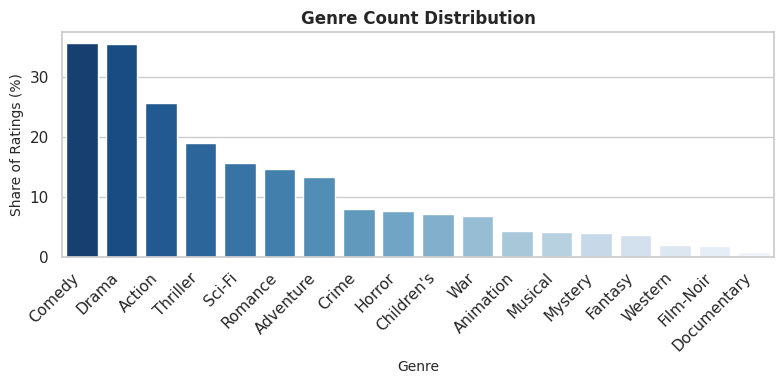

In [248]:
plt.figure(figsize=(8, 4))
sns.barplot(data=genre_df, x='genre', y='count', legend=False, hue='genre', palette='Blues_r')

plt.title('Genre Count Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Genre', fontsize=10)
plt.ylabel('Share of Ratings (%)', fontsize=10)
plt.xticks(rotation=45, ha='right')
# plt.ylim(0, 55)
plt.tight_layout()
plt.show()

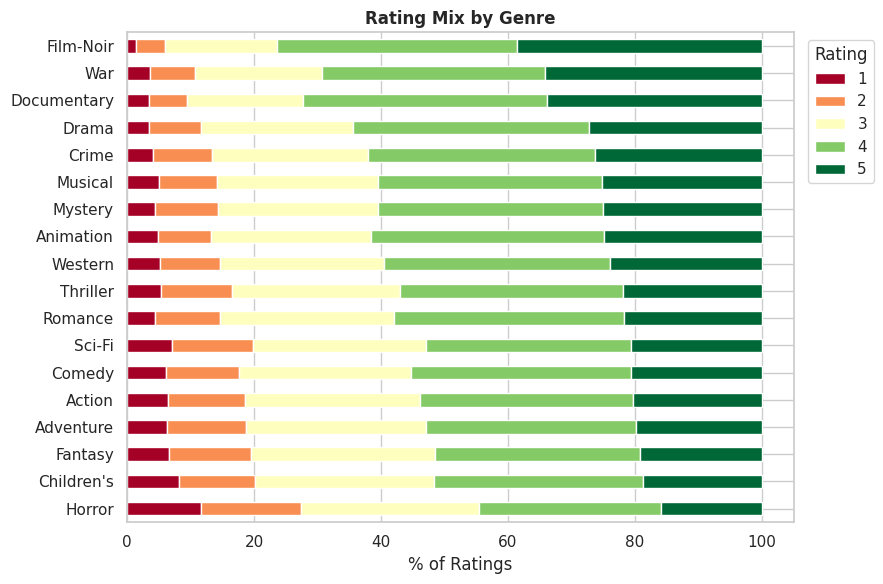

In [249]:
genre_rating = genre_dummies.groupby(df['rating']).sum().T

genre_rating_pct = genre_rating.div(genre_rating.sum(axis=1), axis=0) * 100

genre_rating_pct = genre_rating_pct.sort_values(by=[5, 4], ascending=False)

ax = genre_rating_pct.plot(kind='barh', stacked=True, figsize=(9, 6), colormap='RdYlGn')
ax.invert_yaxis()
ax.set_xlabel('% of Ratings')
ax.set_title('Rating Mix by Genre', fontweight='bold')
ax.legend(title='Rating', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### **Insights:**

- There are 18 genres in the dataset. Every movie belongs to at least one genre and some belong to as many as six, so a single rating can count toward several genres at once. Because of this overlap, the genre shares below add up to more than 100%.

- Comedy and Drama are by far the most common genres, each appearing in about 35% of all ratings, followed by Action at about 25%. At the other end, Western, Film-Noir and Documentary each account for less than 2% of ratings.

- In almost every genre, 4 stars is the most common rating and 1 star the least common. Film-Noir is the exception, with slightly more 5-star than 4-star ratings.

- Film-Noir, War, Documentary and Drama receive the best ratings. Each has fewer than 5% one-star ratings and more than 25% five-star ratings. Film-Noir and Documentary are rarely watched but highly rated. This is likely a selection effect: people who choose a niche genre already know they enjoy it, while mainstream genres reach a broader audience and get more mixed reactions. Drama stands out as both one of the most rated and one of the best liked genres.

- Horror receives the harshest ratings, with about 11% one-star and over a quarter of ratings at 1 or 2 stars. Children's movies come second, possibly because many of their ratings come from adults. The remaining genres have broadly similar rating mixes.

- For the recommender, this means a rating carries a genre effect as well as a user preference. A 4 for a Horror film is a stronger endorsement than a 4 for a Film-Noir film, so comparing raw ratings across genres can be misleading. The data is also dominated by Comedy, Drama and Action, so recommendations will naturally lean toward these genres.

### Most reviewed Movie

In [250]:
movie_rating_cnt = df.groupby('movie_id')['rating'].size().reset_index(name='rating_count')
top_movie = movie_rating_cnt.sort_values(by='rating_count', ascending=False).iloc[0]

top_title = df[df['movie_id'] == top_movie['movie_id']]['title'].iloc[0]

print(f"The most rated movie is '{top_title}' with {top_movie['rating_count']:,} ratings.")

The most rated movie is 'American Beauty (1999)' with 3,428 ratings.


## **EDA Summary**

**Ratings.** The dataset contains 1,000,209 ratings from 6,040 users on 3,706 movies. The user-movie matrix is 95.5% empty, so any two users or movies share only a small number of ratings. The mean rating is 3.58. Four stars is the most common score, followed by 3 and 5, while 2 and 1 stars are the least common. About 84% of all ratings are 3 stars or higher, showing a clear positive rating bias.

**Users.** Every user has rated at least 20 movies, and the average user has rated about 166. The distribution is heavily right-skewed, with a small group of very active users. The 20-rating minimum shows the dataset was pre-filtered, which hides the cold-start problem that a real platform would face. Average ratings per user form a bell shape centered near 3.7 with a long left tail, so users differ noticeably in how generously they rate.

**Movies.** The number of ratings per movie is also heavily right-skewed, with a mean of about 270, a median of 124, and 114 movies rated only once. A further 177 movies in the catalogue have no ratings at all. The scatter plot of average rating against rating count has a funnel shape: averages from a handful of ratings are unreliable, while heavily rated movies settle between 3.5 and 4.5. Based on this, movies with fewer than 75 ratings were removed for modeling. The filtered dataset, `df_model`, keeps 60% of the movies but 96% of the ratings.

**Demographics.** The 25-34 age group contributes the most ratings, followed by 35-44 and 18-24, with Under 18 contributing the least. College/grad students (13.1%) narrowly lead "other" (13.0%) as the most active occupation group. Men account for about 75% of all ratings.

**Content.** Movies span the 1910s to 2000, and the number of ratings grows decade by decade, peaking in the 1990s, which alone accounts for about 53% of ratings. The 2000s bar covers only the year 2000. About 90% of ratings are for movies with one to three genres, two being the most common. Comedy and Drama each appear in about 35% of ratings, though they overlap since a movie can belong to both. Horror and Children's movies receive the highest share of 1 and 2-star ratings, while Film-Noir has the fewest 1-star and the most 5-star ratings of any genre. The most rated movie is American Beauty (1999) with 3,428 ratings.

**What this means for modeling.**
1. High sparsity means similarity scores rest on few shared ratings, which is why rarely rated movies were filtered out before building the user-item matrix.
2. Users rate on different scales, so ratings should be centered on each user's mean before comparing users or movies. Pearson correlation does this automatically, while cosine similarity needs it done explicitly.
3. Popularity is concentrated on a small set of mostly 1990s titles in Comedy, Drama and Action, so the recommender will naturally lean toward them. This popularity bias should be kept in mind when judging the recommendations.
4. Because the data was pre-filtered to active users, the models built here will not show how well the system handles new users with few or no ratings.

### Pearson

**Note:** `df_model` is the ratings data filtered to movies with at least 75 ratings (2,223 movies, 96% of all ratings), since averages and similarity scores based on fewer ratings proved unreliable in the EDA.

In [251]:
df_model.head()

,user_id,movie_id,rating,timestamp,title,genres,gender,age,occupation,zip_code,age_group,occupation_group,genre_count,release_year,decade
0,1,1193,5,2000-12-31 22:12:40,One Flew Over the Cuckoo's Nest (1975),Drama,F,1,10,48067,Under 18,K-12 student,1,1975,1970
1,1,661,3,2000-12-31 22:35:09,James and the Giant Peach (1996),Animation|Children's|Musical,F,1,10,48067,Under 18,K-12 student,3,1996,1990
2,1,914,3,2000-12-31 22:32:48,My Fair Lady (1964),Musical|Romance,F,1,10,48067,Under 18,K-12 student,2,1964,1960
3,1,3408,4,2000-12-31 22:04:35,Erin Brockovich (2000),Drama,F,1,10,48067,Under 18,K-12 student,1,2000,2000
4,1,2355,5,2001-01-06 23:38:11,"Bug's Life, A (1998)",Animation|Children's|Comedy,F,1,10,48067,Under 18,K-12 student,3,1998,1990


In [252]:
rating_matrix = df_model.pivot_table(index=['user_id'], columns=['title'], values='rating')

rating_matrix.head()

title,"'burbs, The (1989)",...And Justice for All (1979),10 Things I Hate About You (1999),101 Dalmatians (1961),101 Dalmatians (1996),12 Angry Men (1957),"13th Warrior, The (1999)",2 Days in the Valley (1996),20 Dates (1998),"20,000 Leagues Under the Sea (1954)",...,You've Got Mail (1998),Young Doctors in Love (1982),Young Frankenstein (1974),Young Guns (1988),Young Guns II (1990),"Young Poisoner's Handbook, The (1995)",Young Sherlock Holmes (1985),Your Friends and Neighbors (1998),Zero Effect (1998),eXistenZ (1999)
user_id,,,,,,,,,,,,,,,,,,,,,
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,5.0,4.0,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [253]:
rating_matrix.shape

(6040, 2223)

In [254]:
total_missing = rating_matrix.isna().sum().sum()
total_cells = rating_matrix.shape[0] * rating_matrix.shape[1]

missing_percentage = (total_missing / total_cells) * 100

print(f"Total missing values: {total_missing:,} ({missing_percentage:.2f}% of all cells)")
print(f"Memory: {rating_matrix.memory_usage().sum() / 1e6:.1f} MB")

Total missing values: 12,466,907 (92.85% of all cells)
Memory: 107.4 MB


In [255]:
target = rating_matrix['Young Guns II (1990)']
corr = rating_matrix.corrwith(target)
corr.sort_values(ascending=False).head(10)

title
Young Guns II (1990)                                1.000000
Seven Beauties (Pasqualino Settebellezze) (1976)    0.968330
Young Guns (1988)                                   0.765377
Deep End of the Ocean, The (1999)                   0.732791
Farinelli: il castrato (1994)                       0.708612
Marnie (1964)                                       0.684967
Ghosts of Mississippi (1996)                        0.664431
Scarlet Letter, The (1995)                          0.646079
Looking for Richard (1996)                          0.633029
Towering Inferno, The (1974)                        0.629817
dtype: float64

In [256]:
n_common = rating_matrix.notna().mul(target.notna(), axis=0).sum()
result = pd.DataFrame({'corr':corr, 'n_common': n_common})
result.sort_values('corr', ascending=False).head(10)

,corr,n_common
title,,
Young Guns II (1990),1.000000,369
Seven Beauties (Pasqualino Settebellezze) (1976),0.968330,4
Young Guns (1988),0.765377,270
"Deep End of the Ocean, The (1999)",0.732791,27
Farinelli: il castrato (1994),0.708612,10
Marnie (1964),0.684967,19
Ghosts of Mississippi (1996),0.664431,37
"Scarlet Letter, The (1995)",0.646079,23
Looking for Richard (1996),0.633029,23


In [257]:
np.errstate(invalid='ignore')

def recommend_pearson(title, n=5, min_common=50):
    target = rating_matrix[title]
    with np.errstate(invalid='ignore'):
        corr = rating_matrix.corrwith(target)
    n_common = rating_matrix.notna().mul(target.notna(), axis=0).sum()

    result = pd.DataFrame({'corr': corr, 'n_common': n_common})
    result = result[result['n_common']>= min_common]
    result = result.drop(title).dropna()
    return result.sort_values(by=['corr','n_common'], ascending=False).reset_index().head(n)

In [258]:
np.errstate(invalid='ignore')
recommend_pearson('Towering Inferno, The (1974)')

,title,corr,n_common
0,Earthquake (1974),0.652263,79
1,Young Guns II (1990),0.629817,63
2,"Amityville Horror, The (1979)",0.622277,75
3,"Poseidon Adventure, The (1972)",0.559877,163
4,Firestarter (1984),0.551656,55


In [259]:
recommend_pearson('Liar Liar (1997)')

,title,corr,n_common
0,Life (1999),0.576081,60
1,Oliver & Company (1988),0.550504,53
2,Spy Hard (1996),0.502376,73
3,Ace Ventura: When Nature Calls (1995),0.495133,214
4,Dead Man on Campus (1998),0.478101,88


## Cosine similarity

**Note:** The EDA showed that users rate on different scales. Some give high ratings to almost everything, while others are much stricter. To remove this bias, each user's average rating is subtracted from all of their ratings before computing cosine similarity. After this centering, a positive value means the user liked a movie more than they usually do, a negative value means they liked it less, and the missing ratings can be filled with 0 to mean "no opinion."

In [260]:
user_mean = rating_matrix.mean(axis=1)
centered_df = rating_matrix.sub(user_mean, axis=0)

centered_df.shape

(6040, 2223)

In [261]:
print(centered_df.notna().sum().sum())
centered_df.mean(axis=1).abs().max()

960013


4.484007555767623e-16

In [262]:
centered_df = centered_df.fillna(0)

In [263]:
from sklearn.metrics.pairwise import cosine_similarity

item_sim = cosine_similarity(centered_df.T)
item_sim_df = pd.DataFrame(item_sim, index=centered_df.columns, columns=centered_df.columns)

user_sim = cosine_similarity(centered_df)
user_sim_df = pd.DataFrame(user_sim, index=centered_df.index, columns=centered_df.index)

print(item_sim_df.shape, user_sim_df.shape)
item_sim_df.iloc[:5, :5]

(2223, 2223) (6040, 6040)


title,"'burbs, The (1989)",...And Justice for All (1979),10 Things I Hate About You (1999),101 Dalmatians (1961),101 Dalmatians (1996)
title,,,,,
"'burbs, The (1989)",1.000000,-0.050237,0.011554,-0.034432,0.047172
...And Justice for All (1979),-0.050237,1.000000,0.002886,0.002490,-0.049966
10 Things I Hate About You (1999),0.011554,0.002886,1.000000,-0.007481,0.044626
101 Dalmatians (1961),-0.034432,0.002490,-0.007481,1.000000,0.078804
101 Dalmatians (1996),0.047172,-0.049966,0.044626,0.078804,1.000000


In [264]:
user_sim_df.iloc[:5,:5]

user_id,1,2,3,4,5
user_id,,,,,
1,1.000000,0.032463,-0.032460,0.016028,-0.017156
2,0.032463,1.000000,0.023682,-0.016706,-0.033190
3,-0.032460,0.023682,1.000000,0.042521,-0.031703
4,0.016028,-0.016706,0.042521,1.000000,-0.002873
5,-0.017156,-0.033190,-0.031703,-0.002873,1.000000


In [265]:
def recommend_cosine(title, n=5):
    top_n = item_sim_df.loc[title,:].drop(title)
    top_n = top_n.sort_values(ascending=False).iloc[:n+1].reset_index()
    top_n.columns = ['title', 'cosine score']
    return top_n

recommend_cosine("Liar Liar (1997)",10)

,title,cosine score
0,Ace Ventura: Pet Detective (1994),0.188425
1,Dumb & Dumber (1994),0.179511
2,Tommy Boy (1995),0.163355
3,Happy Gilmore (1996),0.141032
4,Christmas Vacation (1989),0.133163
5,"Wedding Singer, The (1998)",0.132652
6,"Mask, The (1994)",0.132495
7,Mrs. Doubtfire (1993),0.132164
8,Billy Madison (1995),0.124093
9,Lethal Weapon 2 (1989),0.111228


## Comparison Pearson and Cosine Similarity

In [266]:
pearson_df = recommend_pearson("Liar Liar (1997)",10).rename(columns={'title':'pearson_recc'})
cosine_df = recommend_cosine("Liar Liar (1997)",10).rename(columns={'title':'cosine_sim'})

comparison_df = pd.concat([pearson_df, cosine_df], axis=1)
comparison_df

,pearson_recc,corr,n_common,cosine_sim,cosine score
0,Life (1999),0.576081,60.0,Ace Ventura: Pet Detective (1994),0.188425
1,Oliver & Company (1988),0.550504,53.0,Dumb & Dumber (1994),0.179511
2,Spy Hard (1996),0.502376,73.0,Tommy Boy (1995),0.163355
3,Ace Ventura: When Nature Calls (1995),0.495133,214.0,Happy Gilmore (1996),0.141032
4,Dead Man on Campus (1998),0.478101,88.0,Christmas Vacation (1989),0.133163
5,"Goofy Movie, A (1995)",0.468712,79.0,"Wedding Singer, The (1998)",0.132652
6,Krippendorf's Tribe (1998),0.464559,72.0,"Mask, The (1994)",0.132495
7,Picture Perfect (1997),0.464481,91.0,Mrs. Doubtfire (1993),0.132164
8,Jury Duty (1995),0.461263,62.0,Billy Madison (1995),0.124093
9,Jungle2Jungle (a.k.a. Jungle 2 Jungle) (1997),0.459519,100.0,Lethal Weapon 2 (1989),0.111228


#### **Comparison: Pearson vs Cosine Recommendations for Liar Liar (1997)**

- The two methods produce completely different top 10 lists, with no movies in common.

- Cosine similarity recommends well-known 1990s comedies, including three other Jim Carrey films (Ace Ventura: Pet Detective, Dumb & Dumber, The Mask) and several Adam Sandler films (Happy Gilmore, Billy Madison, The Wedding Singer). These closely match the style and audience of Liar Liar. Pearson correlation recommends lesser-known films such as Life, Oliver & Company and Spy Hard.

- The difference comes from how each method treats missing ratings. Pearson only looks at users who rated both movies, so a match can be based on as few as 50 to 100 people and is easily influenced by chance. Cosine uses the full matrix with missing ratings filled as 0, so a pair only scores highly when many users rated both movies and agreed on them. This makes cosine more stable, but it also favors popular movies with large audiences, which strengthens the popularity bias seen in the EDA.

- The scores themselves are not comparable. Pearson values around 0.5 are not better than cosine values around 0.15, since the two measures are on different scales.

- Overall, cosine gives safer and more recognizable recommendations, while Pearson offers more variety but less reliability. Pearson could be made more reliable by shrinking correlations that are based on few shared raters, for example by multiplying each correlation by n_common / (n_common + 50).

### CSR Matrix (Sparse Representation)

**Note:** 93% of the rating matrix is empty, but a regular (dense) DataFrame still uses memory for every empty cell. A CSR (Compressed Sparse Row) matrix stores only the non-zero values, along with their column positions and where each row starts. Movies are kept as rows so the matrix can be used directly for the KNN recommender below.

In [267]:
from scipy.sparse import csr_matrix

item_csr = csr_matrix(centered_df.T.values)

print(item_csr.shape, item_csr.nnz)

csr_mb = (item_csr.data.nbytes + item_csr.indices.nbytes + item_csr.indptr.nbytes) / 1e6
print(f"CSR: {csr_mb:.1f} MB vs dense: 107.4 MB")

(2223, 6040) 957626
CSR: 11.5 MB vs dense: 107.4 MB


### KNN

In [268]:
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

item_csr = csr_matrix(centered_df.T.values)
print(item_csr.shape, item_csr.nnz)

titles = centered_df.columns
knn = NearestNeighbors(metric='cosine', algorithm='brute').fit(item_csr)

def recommend_knn(title, n=5):
    idx = titles.get_loc(title)
    dist, ind = knn.kneighbors(item_csr[idx], n_neighbors=n + 1)
    res = pd.DataFrame({'title': titles[ind[0]], 'cosine_sim': 1 - dist[0]})
    return res[res['title'] != title].head(n).reset_index(drop=True)

recommend_knn('Liar Liar (1997)',10)

(2223, 6040) 957626


,title,cosine_sim
0,Ace Ventura: Pet Detective (1994),0.188425
1,Dumb & Dumber (1994),0.179511
2,Tommy Boy (1995),0.163355
3,Happy Gilmore (1996),0.141032
4,Christmas Vacation (1989),0.133163
5,"Wedding Singer, The (1998)",0.132652
6,"Mask, The (1994)",0.132495
7,Mrs. Doubtfire (1993),0.132164
8,Billy Madison (1995),0.124093
9,Lethal Weapon 2 (1989),0.111228


### KNN Recommender

In [269]:
knn_df =  recommend_knn('Liar Liar (1997)',10).rename(columns={'title':'knn_recc'})
comparison_df = pd.concat([comparison_df,knn_df], axis=1)
comparison_df

,pearson_recc,corr,n_common,cosine_sim,cosine score,knn_recc,cosine_sim
0,Life (1999),0.576081,60.0,Ace Ventura: Pet Detective (1994),0.188425,Ace Ventura: Pet Detective (1994),0.188425
1,Oliver & Company (1988),0.550504,53.0,Dumb & Dumber (1994),0.179511,Dumb & Dumber (1994),0.179511
2,Spy Hard (1996),0.502376,73.0,Tommy Boy (1995),0.163355,Tommy Boy (1995),0.163355
3,Ace Ventura: When Nature Calls (1995),0.495133,214.0,Happy Gilmore (1996),0.141032,Happy Gilmore (1996),0.141032
4,Dead Man on Campus (1998),0.478101,88.0,Christmas Vacation (1989),0.133163,Christmas Vacation (1989),0.133163
5,"Goofy Movie, A (1995)",0.468712,79.0,"Wedding Singer, The (1998)",0.132652,"Wedding Singer, The (1998)",0.132652
6,Krippendorf's Tribe (1998),0.464559,72.0,"Mask, The (1994)",0.132495,"Mask, The (1994)",0.132495
7,Picture Perfect (1997),0.464481,91.0,Mrs. Doubtfire (1993),0.132164,Mrs. Doubtfire (1993),0.132164
8,Jury Duty (1995),0.461263,62.0,Billy Madison (1995),0.124093,Billy Madison (1995),0.124093
9,Jungle2Jungle (a.k.a. Jungle 2 Jungle) (1997),0.459519,100.0,Lethal Weapon 2 (1989),0.111228,Lethal Weapon 2 (1989),0.111228


### KNN Recommender using Cosine Similarity

The KNN model searches the CSR matrix for the movies whose rating vectors are closest to the chosen movie, using cosine distance (1 minus cosine similarity). Its top 5 recommendations for Liar Liar (1997) are identical to the cosine similarity function above, with the same scores, which confirms both implementations are correct. The advantage of KNN on a sparse matrix is that it does not need the full 2,223 by 2,223 similarity matrix to be computed and stored in advance, so it scales better to larger catalogues.

## Matrix Factorization


In [271]:
from cmfrec import CMF
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

mf_data = df_model[['user_id', 'movie_id', 'rating']].rename(
    columns={'user_id': 'UserId', 'movie_id': 'ItemId', 'rating': 'Rating'})
mf_data['Rating'] = mf_data['Rating'].astype(float)

train, test = train_test_split(mf_data, test_size=0.2, random_state=42,
                               stratify=mf_data['UserId'])

def evaluate(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    return rmse, mape

base_pred = np.full(len(test), train['Rating'].mean())
print("Baseline  RMSE %.4f  MAPE %.2f%%" % evaluate(test['Rating'], base_pred))

model = CMF(method='als', k=4, verbose=False).fit(train)
pred = model.predict(user=test['UserId'].values, item=test['ItemId'].values)
mask = ~np.isnan(pred)
pred = np.clip(pred[mask], 1, 5)
print(f"Predicted {mask.mean():.1%} of test ratings")
print("MF (d=4)  RMSE %.4f  MAPE %.2f%%" % evaluate(test['Rating'][mask], pred))

Baseline  RMSE 1.1096  MAPE 37.46%
Predicted 100.0% of test ratings
MF (d=4)  RMSE 0.8589  MAPE 25.92%


### Matrix Factorization (d = 4)

**Approach.** Matrix factorization learns a small vector of 4 hidden factors for every user and every movie, so that the dot product of a user's vector and a movie's vector approximates the rating that user would give. Unlike the similarity methods above, it learns only from ratings that actually exist, so no missing values need to be filled. The model was trained with the cmfrec library using alternating least squares.

**Train/test split.** 80% of the ratings were used for training and 20% for testing. The split was stratified by user, so every user in the test set also has ratings in the training set. Otherwise the model would have no information about those users and could not make a meaningful prediction for them.

**Results.**

| Model | RMSE | MAPE |
|---|---|---|
| Baseline (predict the average rating) | 1.1096 | 37.46% |
| Matrix factorization (d = 4) | 0.8589 | 25.92% |

The baseline predicts the overall average rating for every user and movie, giving a reference point for judging the model. Matrix factorization reduces RMSE by about 23%, meaning its predictions are typically within about 0.86 stars of the true rating, compared with 1.11 stars for the baseline. MAPE drops by more than 11 percentage points. MAPE should be read with care here: it divides each error by the true rating, so the same mistake on a 1-star rating counts five times more than on a 5-star rating, which makes errors on low ratings dominate the score.

## Similarity using MF Embeddings


In [272]:
id_to_title = df_model.drop_duplicates('movie_id').set_index('movie_id')['title']

item_emb = pd.DataFrame(model.B_, index=id_to_title.loc[model.item_mapping_].values)
item_emb_sim = pd.DataFrame(cosine_similarity(item_emb),
                            index=item_emb.index, columns=item_emb.index)
print(item_emb_sim['Liar Liar (1997)'].drop('Liar Liar (1997)')
      .sort_values(ascending=False).head(5))

user_emb = pd.DataFrame(model.A_, index=model.user_mapping_)
user_emb_sim = pd.DataFrame(cosine_similarity(user_emb),
                            index=user_emb.index, columns=user_emb.index)
user_emb_sim.iloc[:5, :5]

Rocky III (1982)                               0.980985
Indiana Jones and the Temple of Doom (1984)    0.980981
Christmas Vacation (1989)                      0.979365
Rocky II (1979)                                0.978182
Die Hard: With a Vengeance (1995)              0.976779
Name: Liar Liar (1997), dtype: float32


,3822,3272,3971,4021,1497
3822,1.000000,-0.705896,-0.141130,-0.681860,0.116575
3272,-0.705896,1.000000,0.561518,0.178357,0.230894
3971,-0.141130,0.561518,1.000000,0.138815,-0.315713
4021,-0.681860,0.178357,0.138815,1.000000,-0.441863
1497,0.116575,0.230894,-0.315713,-0.441863,1.000000


### Item-Item and User-User Similarity using MF Embeddings (d = 4)

The trained model represents every movie and every user as a 4-dimensional vector. Cosine similarity between these vectors gives a new way to find similar movies and similar users.

**Item-item.** For Liar Liar (1997), the most similar movies by embedding are Rocky III, Indiana Jones and the Temple of Doom, Christmas Vacation, Rocky II and Die Hard: With a Vengeance. These are popular, mainstream 1980s and 1990s entertainment films rather than close matches in genre or star. With only 4 factors, the embeddings capture broad taste groups, and many movies end up pointing in almost the same direction, which is why the similarity scores are all close to 0.98. More factors would allow finer distinctions, such as separating slapstick comedies from action films, at the cost of needing more data to learn reliably.

**User-user.** The user embedding similarities range from strongly negative (around -0.7) to clearly positive (around 0.56), showing that the model separates users with opposite tastes as well as grouping those with similar ones. This could be used to recommend movies liked by a user's closest neighbours.

**Comparison with earlier methods.** Pearson and raw cosine similarity work directly on ratings and found close matches such as other Jim Carrey comedies, while the d = 4 embeddings give broader, more general recommendations. In exchange, the embeddings are very compact (4 numbers per movie instead of 6,040) and also power rating predictions, which the similarity methods cannot do.

## Visualizing Movie Embeddings (d = 2)

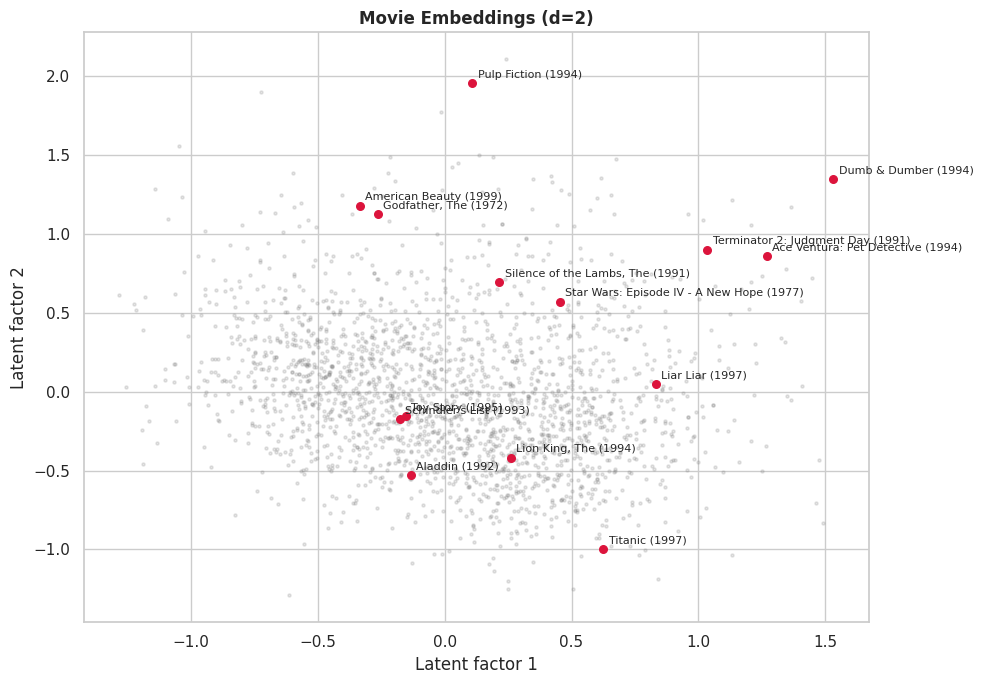

In [274]:
model2 = CMF(method='als', k=2, verbose=False).fit(train)
emb2 = pd.DataFrame(model2.B_, columns=['x', 'y'],
                    index=id_to_title.loc[model2.item_mapping_].values)

picks = ['Toy Story (1995)', 'Lion King, The (1994)', 'Aladdin (1992)',
         'Liar Liar (1997)', 'Dumb & Dumber (1994)', 'Ace Ventura: Pet Detective (1994)',
         "Schindler's List (1993)", 'Godfather, The (1972)', 'Pulp Fiction (1994)',
         'Silence of the Lambs, The (1991)', 'Star Wars: Episode IV - A New Hope (1977)',
         'Terminator 2: Judgment Day (1991)', 'Titanic (1997)', 'American Beauty (1999)']
picks = [t for t in picks if t in emb2.index]

plt.figure(figsize=(10, 7))
plt.scatter(emb2['x'], emb2['y'], s=5, alpha=0.2, color='grey')
for t in picks:
    plt.scatter(*emb2.loc[t], color='crimson', s=30)
    plt.annotate(t, emb2.loc[t], fontsize=8, xytext=(4, 4), textcoords='offset points')
plt.title('Movie Embeddings (d=2)', fontweight='bold')
plt.xlabel('Latent factor 1'); plt.ylabel('Latent factor 2')
plt.tight_layout(); plt.show()

### Movie Embeddings with d = 2

Training the model with only 2 factors lets every movie be plotted as a point, with nearby points representing movies that users tend to rate similarly. The two axes are learned by the model and have no fixed meaning, but clear patterns appear:

- **Jim Carrey comedies cluster together.** Dumb & Dumber, Ace Ventura and Liar Liar all sit on the far right, close to Terminator 2. This side of the plot holds broad, mainstream comedy and action.
- **Acclaimed dramas sit together on the opposite side.** The Godfather and American Beauty are almost on top of each other in the upper left, away from the comedies.
- **Family and animated films group at the bottom.** Aladdin and The Lion King are close neighbours, with Titanic further down. The lower half appears to capture family-friendly and romantic, broad-appeal titles, while the top holds edgier, more adult films such as Pulp Fiction.
- **Two dimensions cannot separate everything.** Toy Story and Schindler's List land almost in the same spot, even though they are very different films. Both are near-universally well liked, and two factors are not enough to tell them apart. This is why more factors (such as d = 4 or higher) give better predictions.

Even though the model was only given user IDs, movie IDs and ratings, it discovered genre and audience structure on its own. Other ways to visualize higher-dimensional embeddings include PCA or t-SNE, which project the d = 4 vectors down to 2 dimensions instead of training a separate 2-factor model.

## Questionnaire

1. **Age group that watched and rated the most movies:** 25-34 (about 40% of ratings).
2. **Profession that watched and rated the most movies:** College/grad students (13.1% of ratings), narrowly ahead of "other" (13.0%), an unspecified category.
3. **Most users are male (T/F):** True. Men account for about 75% of ratings.
4. **Decade in which most movies were released:** b. 90s.
5. **Movie with the maximum number of ratings:** American Beauty (1999), with 3,428 ratings.
6. **Top 3 movies similar to Liar Liar (item-based, Pearson):** Life (1999), Oliver & Company (1988), Spy Hard (1996). With cosine similarity, the top 3 are Ace Ventura: Pet Detective (1994), Dumb & Dumber (1994) and Tommy Boy (1995).
7. **Collaborative filtering approaches:** Memory-based and model-based. Memory-based methods are further split into user-based and item-based.
8. **Ranges:** Pearson correlation ranges from -1 to 1. Cosine similarity also ranges from -1 to 1, and from 0 to 1 when all values are non-negative, as with raw ratings.
9. **Matrix factorization results (d = 4):** RMSE 0.8589 and MAPE 25.92%, compared with RMSE 1.1096 and MAPE 37.46% for the baseline.
10. **CSR representation of [[1, 0], [3, 7]]:** data = [1, 3, 7], indices = [0, 0, 1], indptr = [0, 1, 3].